
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of ETFs and S&P 500 stocks.  Construct portfolios from the ETFs and S&P 500 and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['sp500-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='3 Yr', standard_deviation='SD 3 Yr')
df.head(100)

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,MMM,3M,US Stocks:Industrials,70.98,13.35,13.43,16.33,31.47,5.05,16.08,10.41,21.70,28.11,28.27,31.47,28.11,1.12
1,AOS,A. O. Smith,US Stocks:Industrials,31.56,-38.66,-14.77,-12.50,-2.95,-1.36,30.88,13.28,26.55,23.84,29.87,-2.95,23.84,-70.33
2,ABT,Abbott Laboratories,US Stocks:Healthcare,206.62,-4.03,-12.47,-13.24,4.43,-0.38,19.66,10.44,30.58,23.49,22.93,4.43,23.49,0.19
3,ABBV,AbbVie,US Stocks:Healthcare,95.05,24.96,26.60,27.74,24.43,20.90,22.37,10.99,20.36,20.94,22.89,24.43,20.94,1.17
4,ACN,Accenture,US Stocks:Technology,10.71,-14.04,-24.74,-25.13,-14.04,-9.14,33.85,16.62,56.40,38.16,34.93,-14.04,38.16,-535.77
5,ADBE,Adobe Inc.,US Stocks:Technology,59.98,23.42,-18.19,-18.53,-18.10,-14.75,39.38,18.76,42.19,35.43,38.28,-18.10,35.43,-641.28
6,AMD,Advanced Micro Devices,US Stocks:Technology,-33.77,440.78,178.57,186.08,62.04,34.79,54.82,30.67,100.92,70.47,68.08,62.04,70.47,0.88
7,AES,AES Corporation,US Stocks:Utilities,6.61,-23.74,15.74,16.07,-2.34,-5.81,2.83,1.40,26.93,40.85,39.28,-2.34,40.85,-95.59
8,AFL,Aflac,US Stocks:Financials,17.75,8.65,10.75,10.04,19.28,18.28,19.58,15.29,15.00,18.30,20.75,19.28,18.30,1.05
9,A,Agilent Technologies,US Stocks:Healthcare,67.29,61.99,30.66,34.37,9.73,-1.06,27.59,14.35,29.52,30.37,29.04,9.73,30.37,0.32


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Subclass', num_per_group=2)
rank_filtered = rank
#rank_filtered = rank.loc[(rank['3 mo'] > 0) & rank['1 Yr'] > 0]
rank_filtered

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
169,ETR,Entergy,US Stocks:Utilities,-9.44,-0.28,21.03,21.82,34.65,17.06,15.97,10.96,19.18,18.60,20.54,34.65,18.60,1.86
472,VST,Vistra Corp.,US Stocks:Utilities,-46.11,-37.50,-29.18,-27.97,67.01,52.67,42.50,30.72,22.05,51.00,43.64,67.01,51.00,1.31
401,SNDK,Sandisk,US Stocks:Technology,-41.09,446.26,2965.61,3036.11,2965.61,2965.61,95.42,44.58,175.83,160.86,160.86,2965.61,160.86,18.44
487,WDC,Western Digital,US Stocks:Technology,-43.98,170.23,471.09,481.17,145.94,59.03,80.40,54.91,81.04,61.00,59.01,145.94,61.00,2.39
485,WELL,Welltower,US Stocks:Real Estate,83.47,34.03,44.01,46.60,46.07,26.08,20.57,13.45,25.35,19.90,24.34,46.07,19.90,2.32
462,VTR,Ventas,US Stocks:Real Estate,43.19,16.36,38.74,40.93,32.56,14.73,27.03,20.69,17.79,21.13,27.12,32.56,21.13,1.54
328,NEM,Newmont,US Stocks:Materials,84.50,-2.24,78.67,84.59,51.67,21.30,50.88,20.13,48.21,39.96,39.60,51.67,39.96,1.29
419,STLD,Steel Dynamics,US Stocks:Materials,-33.19,49.23,78.96,81.17,33.48,30.45,43.34,31.44,34.73,31.08,39.30,33.48,31.08,1.08
236,HWM,Howmet Aerospace,US Stocks:Industrials,10.84,1.96,51.10,52.46,75.81,53.23,26.26,18.92,31.42,35.40,33.36,75.81,35.40,2.14
119,FIX,Comfort Systems USA,US Stocks:Industrials,-52.28,13.22,114.39,128.77,103.59,83.56,49.12,31.93,50.57,48.66,44.85,103.59,48.66,2.13


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# put your "age" in bonds and the rest in stocks
age_portfolio = {
    'Title': 'Age Portfolio',
    'SPY': 0.50,
    'AGG': 0.50
}

# put your "age" in Short Term Treasuries and the rest in stocks
age2_portfolio = {
    'Title': 'Age2 Portfolio',
    'SPY': 0.50,
    'BIL': 0.50
}

# top dogs - top performer by sharpe ratio in each Asset Class, equal weights
top_dog_portfolio = {
    'Title': 'Top Dog Portfolio',
    'XLK': 1/7,
    'IYR': 1/7,
    'VPL': 1/7,
    'FXY': 1/7,
    'PALL': 1/7,
    'BIL': 1/7,
    'SHY': 1/7
}

# 50% S&P 500, 50% long term treasury
fifty_fifty_portfolio = {
    'Title': 'Fifty Fifty Portfolio',
    'SPY': 1/2,
    'TLT': 1/2
}

# 1/3 S&P 500, 1/3 bonds, 1/3 fixed income
thirds_portfolio = {
    'Title': 'Thirds Portfolio',
    'SPY': 1/3,
    'AGG': 1/3,
    'JPST': 1/3
}

# Dave Ramsey: 25% Growth and income, 25% Growth, 25% Aggressive growth, 25% International
dave_ramsey_portfolio = {
    'Title': 'Dave Ramsey Portfolio',
    'VTI': 1/4,
    'SPY': 1/4,
    'QQQ': 1/4,
    'VXUS': 1/4   
}

# Warren Buffett Retirement Fund: 90% S&P500, 10% Short Term Treasuries (sub General Account)
warren_buffett_portfolio = {
    'Title': 'Warren Buffet Portfolio',
    'SPY': 0.90,
    'BIL': 0.10
}

# https://www.forbes.com/sites/baldwin/2016/07/25/eight-famous-portfolios/#42c50d7d5cce
# american households: 25% real estate, 30% stocks, 30% fixed income, 5% cash, 10% alternatives
american_households_portfolio = {
    'Title': 'American Households Portfolio',
    'IYR': 0,
    'SPY': 0,
    'JPST': 0.43,
    'BIL': 0.51,
    'GLD': 0.06
}

# janet yellen: 50% fixed income, 40% S&P500, 10% cash
janet_yellen_portfolio = {
    'Title': 'Janet Yellen Portfolio',
    'JPST': 0.50,
    'SPY': 0.40,
    'BIL': 0.10
}

# risk off: 100% fixed income divided between risk free asset, bond fund, and money market 
risk_off_portfolio = {
    'Title': 'Risk Off Portfolio',
    'BIL': 1/3,
    'AGG': 1/3,
    'JPST': 1/3
}

# risk on: 100% US stocks bevided between large, emerging markets, and small cap
risk_on_portfolio = {
    'Title': 'Risk On Portfolio',
    'SPY': 1/3,
    'EEM':1/3,
}

# everything ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank_filtered['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

# top 10
top10_portfolio = {
    'Title': 'Ranked Portfolio'
}
top10 = list(rank_filtered['Investment Option'])[:10]
top10_portfolio.update(dict.fromkeys(top10, 1/len(top10)))

### Custom Portfolios

In [8]:
# my portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = ranked_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': 'Annual Returns'},
    'Investment Option': {'weight_by': 'Equal'},
}
#weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,ETR,VST,SNDK,WDC,WELL,VTR,NEM,STLD,HWM,FIX,...,C,TRGP,WMB,CASY,PM,HLT,RL,T,GOOGL,Ranked Portfolio
Annual Returns,34.65,67.01,2965.61,145.94,46.07,32.56,51.67,33.48,75.81,103.59,...,52.49,54.28,33.72,46.06,32.26,29.38,48.28,29.10,38.24,307.83
Std Dev,18.60,51.00,160.86,61.00,19.90,21.13,39.96,31.08,35.40,48.66,...,24.13,27.81,19.72,25.33,22.46,18.06,32.86,23.09,31.26,27.42
Sharpe Ratio,1.86,1.31,18.44,2.39,2.32,1.54,1.29,1.08,2.14,2.13,...,2.18,1.95,1.71,1.82,1.44,1.63,1.47,1.26,1.22,11.23
Weight,0.04,0.04,0.09,0.09,0.03,0.03,0.03,0.03,0.06,0.06,...,0.06,0.05,0.05,0.02,0.02,0.04,0.04,0.06,0.06,1.00
Worst Typical Down Year,-2.55,-34.99,2643.89,23.94,6.27,-9.70,-28.25,-28.68,5.01,6.27,...,4.23,-1.34,-5.72,-4.60,-12.66,-6.74,-17.44,-17.08,-24.28,252.99
Black Swan,-21.15,-85.99,2483.03,-37.06,-13.63,-30.83,-68.21,-59.76,-30.39,-42.39,...,-19.90,-29.15,-25.44,-29.93,-35.12,-24.80,-50.30,-40.17,-55.54,225.56


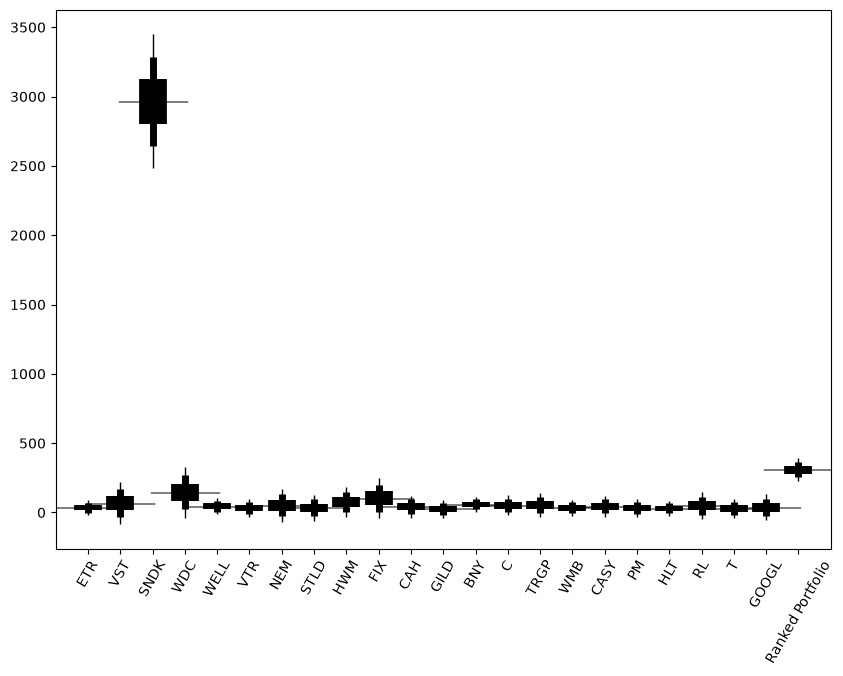

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

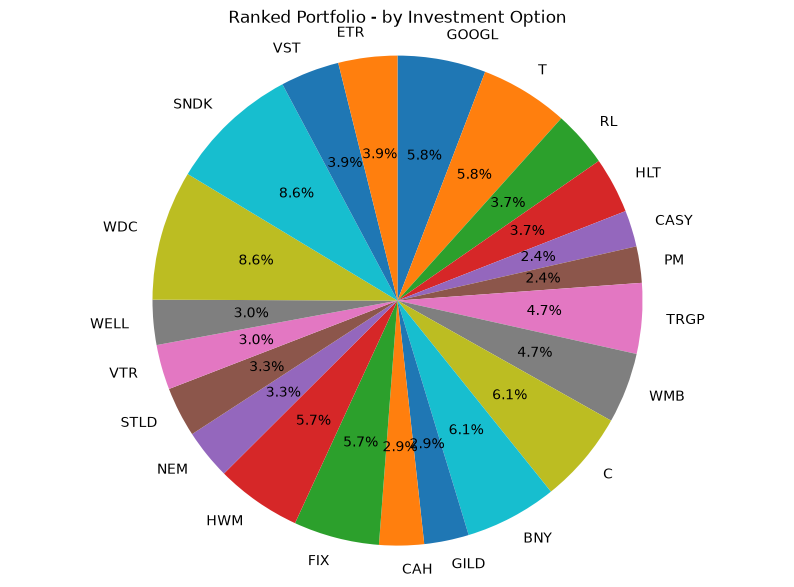

GOOGL   0.06
T       0.06
RL      0.04
HLT     0.04
CASY    0.02
PM      0.02
TRGP    0.05
WMB     0.05
C       0.06
BNY     0.06
GILD    0.03
CAH     0.03
FIX     0.06
HWM     0.06
NEM     0.03
STLD    0.03
VTR     0.03
WELL    0.03
WDC     0.09
SNDK    0.09
VST     0.04
ETR     0.04



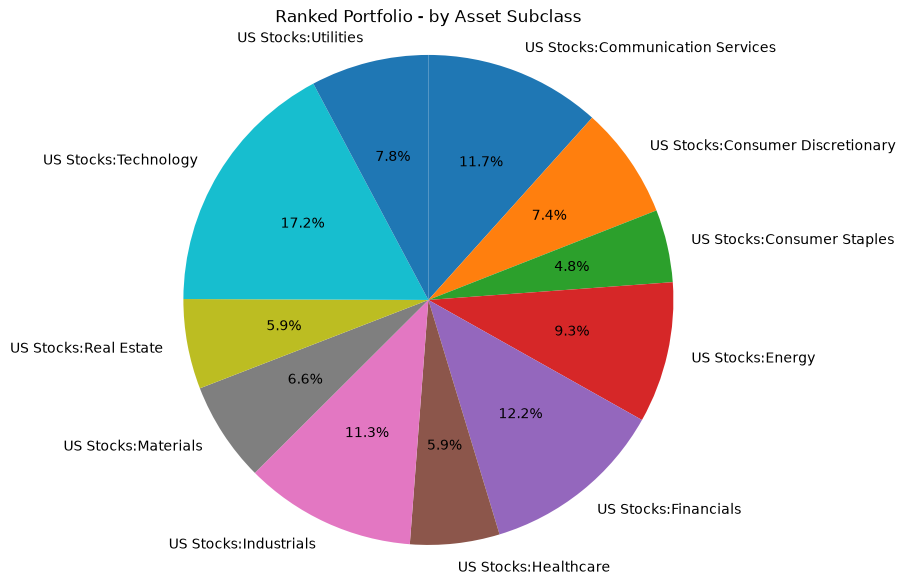

US Stocks:Communication Services   0.12
US Stocks:Consumer Discretionary   0.07
US Stocks:Consumer Staples         0.05
US Stocks:Energy                   0.09
US Stocks:Financials               0.12
US Stocks:Healthcare               0.06
US Stocks:Industrials              0.11
US Stocks:Materials                0.07
US Stocks:Real Estate              0.06
US Stocks:Technology               0.17
US Stocks:Utilities                0.08



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Subclass'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Ranked Portfolio Weights:
    ETR                            0.0389
    VST                            0.0389
    SNDK                           0.0858
    WDC                            0.0858
    WELL                           0.0297
    VTR                            0.0297
    NEM                            0.0330
    STLD                           0.0330
    HWM                            0.0566
    FIX                            0.0566
    CAH                            0.0295
    GILD                           0.0295
    BNY                            0.0608
    C                              0.0608
    TRGP                           0.0465
    WMB                            0.0465
    CASY                           0.0240
    PM                             0.0240
    HLT                            0.0370
    RL                             0.0370
    T                              0.0583
    GOOGL                          0.0583


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).